In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Bidirectional, Dense

# Load the data
def load_data(file_path):
    with open(file_path, 'r', encoding='utf-8') as file:
        lines = file.readlines()
    sentences, labels = [], []
    sentence, sentence_labels = [], []
    for line in lines:
        if line.strip():
            word, label = line.strip().split('\t')
            sentence.append(word)
            sentence_labels.append(label)
        else:
            sentences.append(sentence)
            labels.append(sentence_labels)
            sentence, sentence_labels = [], []
    return sentences, labels

train_sentences, train_labels = load_data('train')
dev_sentences, dev_labels = load_data('dev')
test_sentences, test_labels = load_data('test')

# Create vocabulary and label-to-index dictionaries
def create_vocab_mappings(sentences, labels):
    words, tags = set(), set()
    for sentence, label in zip(sentences, labels):
        words.update(sentence)
        tags.update(label)
    word2idx = {word: idx + 1 for idx, word in enumerate(words)}
    tag2idx = {tag: idx for idx, tag in enumerate(tags)}
    return word2idx, tag2idx

# Create vocabulary and label-to-index dictionaries
word2idx, tag2idx = create_vocab_mappings(train_sentences + dev_sentences + test_sentences, train_labels + dev_labels + test_labels)

# Add the unknown word token to the word-to-index dictionary with index 0
word2idx['en:'] = 0
idx2word = {idx: word for word, idx in word2idx.items()}
idx2tag = {idx: tag for tag, idx in tag2idx.items()}

# Convert sentences and labels to numerical representation
def convert_to_indices(sentences, labels, word2idx, tag2idx):
    X, y = [], []
    for sentence, label in zip(sentences, labels):
        X.append([word2idx[word] for word in sentence])
        y.append([tag2idx[tag] for tag in label])
    return X, y

train_X, train_y = convert_to_indices(train_sentences, train_labels, word2idx, tag2idx)
dev_X, dev_y = convert_to_indices(dev_sentences, dev_labels, word2idx, tag2idx)
test_X, test_y = convert_to_indices(test_sentences, test_labels, word2idx, tag2idx)

# Pad sequences to the same length
max_sequence_length = max(len(seq) for seq in train_X + dev_X + test_X)
train_X = pad_sequences(train_X, maxlen=max_sequence_length, padding='post')
train_y = pad_sequences(train_y, maxlen=max_sequence_length, padding='post')
dev_X = pad_sequences(dev_X, maxlen=max_sequence_length, padding='post')
dev_y = pad_sequences(dev_y, maxlen=max_sequence_length, padding='post')
test_X = pad_sequences(test_X, maxlen=max_sequence_length, padding='post')
test_y = pad_sequences(test_y, maxlen=max_sequence_length, padding='post')

# Convert labels to one-hot vectors
num_tags = len(tag2idx)
train_y = to_categorical(train_y, num_classes=num_tags)
dev_y = to_categorical(dev_y, num_classes=num_tags)
test_y = to_categorical(test_y, num_classes=num_tags)

# Build and train the RNN model
def build_rnn_model(num_words, num_tags, max_sequence_length):
    model = Sequential()
    model.add(Embedding(input_dim=num_words, output_dim=64, input_length=max_sequence_length))
    model.add(SimpleRNN(128, return_sequences=True))
    model.add(Dense(num_tags, activation='softmax'))
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

rnn_model = build_rnn_model(len(word2idx)+1, num_tags, max_sequence_length)
rnn_model.summary()

rnn_model.fit(train_X, train_y, validation_data=(dev_X, dev_y), epochs=10, batch_size=32)





Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 439, 64)           3499008   
                                                                 
 simple_rnn (SimpleRNN)      (None, 439, 128)          24704     
                                                                 
 dense (Dense)               (None, 439, 7)            903       
                                                                 
Total params: 3,524,615
Trainable params: 3,524,615
Non-trainable params: 0
_________________________________________________________________
Epoch 1/10
625/625 [==============================] - 100s 157ms/step - loss: 0.0580 - accuracy: 0.9849 - val_loss: 0.0254 - val_accuracy: 0.9919
Epoch 2/10
625/625 [==============================] - 116s 186ms/step - loss: 0.0182 - accuracy: 0.9942 - val_loss: 0.0150 - val_accuracy: 0.9952
Epoch 3/10
625/625

In [7]:
# Evaluate the model
def evaluate_model(model, X, y, idx2tag):
    y_pred = model.predict(X)
    y_pred_labels = np.argmax(y_pred, axis=-1)
    y_true_labels = np.argmax(y, axis=-1)

    # Calculate F1 score for NER task
    def f1_score(y_true, y_pred):
        true_positives = np.sum(np.logical_and(y_true == 1, y_pred == 1))
        false_positives = np.sum(np.logical_and(y_true == 0, y_pred == 1))
        false_negatives = np.sum(np.logical_and(y_true == 1, y_pred == 0))
        precision = true_positives / (true_positives + false_positives + 1e-10)
        recall = true_positives / (true_positives + false_negatives + 1e-10)
        f1 = 2 * (precision * recall) / (precision + recall + 1e-10)
        return f1

    f1 = f1_score(y_true_labels, y_pred_labels)
    print("F1 Score:", f1)


print("\nEvaluating RNN Model:")
evaluate_model(rnn_model, test_X, test_y, idx2tag)


Evaluating RNN Model:
313/313 [==============================] - 17s 54ms/step
F1 Score: 0.9229651162290531


In [20]:
# Qualitative analysis - Manually inspect errors and categorize them

def qualitative_analysis(model, X, y_true, idx2tag):
    y_pred = model.predict(X)
    y_pred_labels = np.argmax(y_pred, axis=-1)
    y_true_labels = np.argmax(y_true, axis=-1)

    num_errors_to_inspect = 20
    error_count = 0
    for i in range(len(X)):
        if error_count >= num_errors_to_inspect:
            break

        true_labels = [idx2tag[idx] for idx in y_true_labels[i] if idx != 0]
        pred_labels = [idx2tag[idx] for idx in y_pred_labels[i] if idx != 0]

        if true_labels != pred_labels:
            error_count += 1
            print("\nSample", error_count)
            print("Input Sentence:", " ".join([idx2word[idx] for idx in X[i] if idx != 0]))
            print("True Labels:", true_labels)
            print("Predicted Labels:", pred_labels)

# Perform qualitative analysis on the RNN model
print("\nQualitative Analysis on RNN Model:")
qualitative_analysis(rnn_model, test_X, test_y, idx2tag)



Qualitative Analysis on RNN Model:
313/313 [==============================] - 21s 65ms/step

Sample 1
Input Sentence: en:: en:Kanye en:West en:featuring en:Jamie en:Foxx en:— en:`` en:Gold en:Digger en:'' en:( en:2005 en:)
True Labels: ['O', 'B-PER', 'I-PER', 'O', 'B-PER', 'I-PER', 'O', 'O', 'B-ORG', 'I-ORG', 'O', 'O', 'O', 'O']
Predicted Labels: ['O', 'B-ORG', 'O', 'B-PER', 'I-PER', 'O', 'O', 'B-ORG', 'I-ORG', 'O', 'O', 'O', 'O']

Sample 2
Input Sentence: en:Blacktown en:railway en:station
True Labels: ['B-ORG', 'I-ORG', 'I-ORG']
Predicted Labels: ['I-ORG', 'I-ORG']

Sample 3
Input Sentence: en:'' en:Mycalesis en:perseus en:lalassis en:'' en:( en:Hewitson en:, en:1864 en:)
True Labels: ['O', 'I-LOC', 'I-LOC', 'O', 'O', 'O', 'O', 'O', 'O']
Predicted Labels: ['O', 'B-ORG', 'I-ORG', 'I-ORG', 'O', 'O', 'O', 'O', 'O', 'O']

Sample 4
Input Sentence: en:Jonny en:Lee en:Miller en:- en:Eli en:Stone en:''
True Labels: ['B-PER', 'I-PER', 'I-PER', 'O', 'B-ORG', 'I-ORG', 'O']
Predicted Labels: ['

313/313 [==============================] - 10s 32ms/step


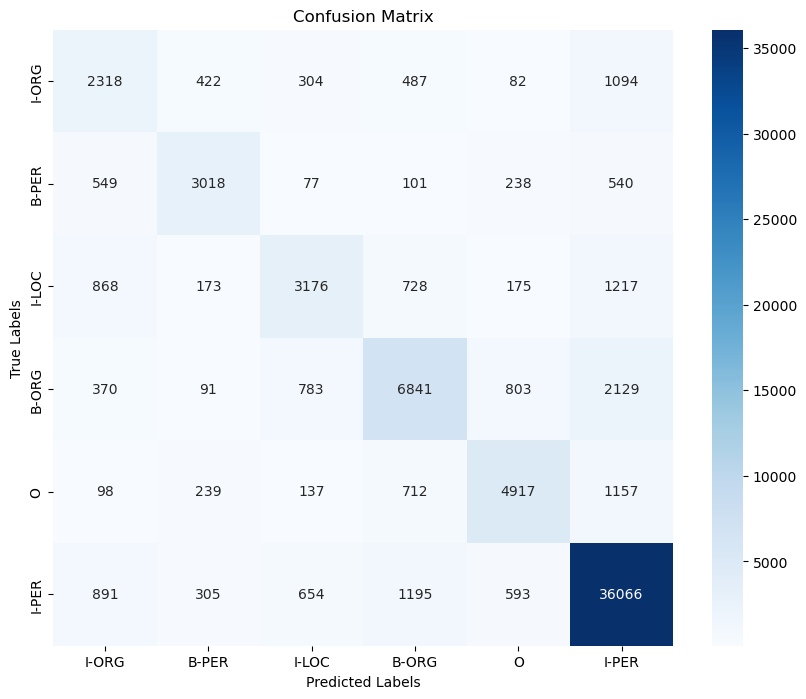

In [30]:

from sklearn.metrics import confusion_matrix

# Function to evaluate the model and get predicted labels
def evaluate_model_with_labels(model, X, y_true, idx2tag):
    y_pred = model.predict(X)
    y_pred_labels = np.argmax(y_pred, axis=-1)
    y_true_labels = np.argmax(y_true, axis=-1)

    # Convert integer labels to tag labels
    y_true_tags = [[idx2tag[idx] for idx in sentence if idx != 0] for sentence in y_true_labels]
    y_pred_tags = [[idx2tag[idx] for idx in sentence if idx != 0] for sentence in y_pred_labels]

    return y_true_tags, y_pred_tags

# Get true and predicted labels for test data
true_labels, predicted_labels = evaluate_model_with_labels(rnn_model, test_X, test_y, idx2tag)

def create_confusion_matrix(true_labels, predicted_labels):
    # Create a list of all unique tags from true_labels and predicted_labels
    all_tags = list(set(tag for true_sentence, pred_sentence in zip(true_labels, predicted_labels) for tag in true_sentence + pred_sentence))
    all_tags.sort()

    # Initialize the confusion matrix with zeros
    num_tags = len(all_tags)
    confusion = np.zeros((num_tags, num_tags), dtype=int)

    # Create dictionaries to map tags to indices
    tag_to_index = {tag: i for i, tag in enumerate(all_tags)}

    for true_sentence, pred_sentence in zip(true_labels, predicted_labels):
        for true_tag, pred_tag in zip(true_sentence, pred_sentence):
            true_index = tag_to_index.get(true_tag, -1)
            pred_index = tag_to_index.get(pred_tag, -1)
            if true_index != -1 and pred_index != -1:
                confusion[true_index, pred_index] += 1

    return confusion



# Call the function to create the confusion matrix
confusion_matrix = create_confusion_matrix(true_labels, predicted_labels)


# Function to plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(confusion_matrix, tags):
    plt.figure(figsize=(10, 8))
    sns.heatmap(confusion_matrix, annot=True, fmt="d", xticklabels=tags, yticklabels=tags, cmap='Blues')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()

# Plot the confusion matrix
all_tags = list(set([tag for sentence in true_labels for tag in sentence]))
plot_confusion_matrix(confusion_matrix, all_tags)

In [31]:
import pandas as pd

# Call the function to create the confusion matrix
confusion_matrix = create_confusion_matrix(true_labels, predicted_labels)

# Function to print the confusion matrix as a table
def print_confusion_matrix(confusion_matrix, tags):
    df_cm = pd.DataFrame(confusion_matrix, index=tags, columns=tags)
    print(df_cm)

# Print the confusion matrix
print("\nConfusion Matrix:")
all_tags = list(set([tag for sentence in true_labels for tag in sentence]))
print_confusion_matrix(confusion_matrix, all_tags)



Confusion Matrix:
       I-ORG  B-PER  I-LOC  B-ORG     O  I-PER
I-ORG   2318    422    304    487    82   1094
B-PER    549   3018     77    101   238    540
I-LOC    868    173   3176    728   175   1217
B-ORG    370     91    783   6841   803   2129
O         98    239    137    712  4917   1157
I-PER    891    305    654   1195   593  36066


In [32]:
unique_true_tags = set([tag for sentence in true_labels for tag in sentence])
unique_pred_tags = set([tag for sentence in predicted_labels for tag in sentence])

print("Unique True Tags:", unique_true_tags)
print("Unique Predicted Tags:", unique_pred_tags)


Unique True Tags: {'I-ORG', 'B-PER', 'I-LOC', 'B-ORG', 'O', 'I-PER'}
Unique Predicted Tags: {'I-ORG', 'B-PER', 'I-LOC', 'B-ORG', 'O', 'I-PER'}
